# IND320 — Project Work, Part 3

**GitHub repository:** https://github.com/isach07/IND320_isachstevik

**Streamlit app:** https://ind320isachstevik-dsj69wxyp9oamezekyfwal.streamlit.app

**Video presentation:** https://www.youtube.com/watch?v=XsTff5Fe0B8

In [3]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

## Sampling 1000 random locations

The goal is 1000 random locations in Norway, each labelled with the electricity price area and the precipitation area it belongs to, using the same areas as the Magasinstatistikk data.

The price areas match directly: NO 1 in the shapefile is EL 1 in Magasinstatistikk. The NVE regions have to be combined, because Magasinstatistikk only has three precipitation areas with data, while the shapefile has five regions.


In [4]:
import geopandas as gpd

# Both shapefiles are in EPSG:25833 (metres). The encoding is set so RØ is read correctly.
price_areas = gpd.read_file("../Data/Budområder/Budområder.shp")[["budomr", "geometry"]]
nve_regions = gpd.read_file("../Data/NVE_Region/NVE_Region.shp", encoding="utf-8")[["REGION", "REGIONNAVN", "geometry"]]

# same labels as the area column in the Magasinstatistikk data from part 2
price_areas["el_area"] = price_areas["budomr"].str.replace("NO", "EL")

REGION_TO_VASS = {"RS": "VASS 1", "RØ": "VASS 1", "RV": "VASS 2", "RM": "VASS 3", "RN": "VASS 3"}
nve_regions["vass_area"] = nve_regions["REGION"].map(REGION_TO_VASS)
nve_regions.drop(columns="geometry")


,REGION,REGIONNAVN,vass_area
0,RV,Region Vest,VASS 2
1,RM,Region Midt-Norge,VASS 3
2,RN,Region Nord,VASS 3
3,RØ,Region Øst,VASS 1
4,RS,Region Sør,VASS 1


NVE describes VASS 3 as Midt Norge and lists a separate VASS 4 for the north, but VASS 4 has no data. The check below shows that VASS 1–VASS 3 add up to the capacity of the whole country, so VASS 3 must include the north. That is why RM and RN belong together.


In [5]:
NVE_BASE = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk"

reservoirs = pd.DataFrame(requests.get(f"{NVE_BASE}/HentOffentligData", timeout=60).json())
latest = reservoirs[reservoirs["dato_Id"] == reservoirs["dato_Id"].max()]

# reservoir capacity for each VASS area, compared with the total for Norway (NO)
capacity = latest[latest["omrType"].isin(["NO", "VASS"])].set_index(["omrType", "omrnr"])["kapasitet_TWh"].sort_index()
print(capacity.round(2))
print(f"Sum of VASS: {capacity['VASS'].sum():.2f} TWh")


omrType  omrnr
NO       0        87.44
VASS     1        36.04
         2        23.24
         3        28.16
Name: kapasitet_TWh, dtype: float64
Sum of VASS: 87.44 TWh


In [6]:
SEED = 320   # fixed so the same 1000 locations come back on every run
N_POINTS = 1000

# The outlines of the two shapefiles differ slightly, so only keep the area covered by both.
# This also gives one piece per combination of price area and region.
both = gpd.overlay(price_areas, nve_regions, how="intersection", keep_geom_type=True)

# Uniform over the area, so a larger area gets more locations
norway = gpd.GeoSeries([both.union_all()], crs=both.crs)
points = norway.sample_points(N_POINTS, rng=SEED).explode(ignore_index=True)

# look up which piece each location falls in
samples = gpd.sjoin(gpd.GeoDataFrame(geometry=points), both, predicate="within", how="left")

# longitude and latitude, for looking the locations up in other data sources
lonlat = samples.geometry.to_crs(epsg=4326)
samples["lon"] = lonlat.x
samples["lat"] = lonlat.y

samples = samples[["lon", "lat", "el_area", "REGION", "vass_area", "geometry"]]
samples.head()


,lon,lat,el_area,REGION,vass_area,geometry
0,7.448009,58.865260,EL 2,RS,VASS 1,POINT (65015.967 6549641.148)
1,10.980912,61.613299,EL 1,RØ,VASS 1,POINT (286923.665 6837681.112)
2,10.600920,62.155378,EL 1,RØ,VASS 1,POINT (270889.457 6899272.118)
3,10.969834,59.002215,EL 1,RØ,VASS 1,POINT (268562.202 6547280.301)
4,7.321573,59.013810,EL 2,RS,VASS 1,POINT (59656.024 6566943.217)


In [7]:
# every location should have exactly one price area and one precipitation area
assert len(samples) == N_POINTS
assert samples[["el_area", "vass_area"]].notna().all().all()

# number of locations per combination of areas
pd.crosstab(samples["el_area"], samples["vass_area"], margins=True)


vass_area,VASS 1,VASS 2,VASS 3,All
el_area,,,,
EL 1,126,0,3,129
EL 2,119,19,0,138
EL 3,27,77,93,197
EL 4,0,0,450,450
EL 5,19,67,0,86
All,291,163,546,1000


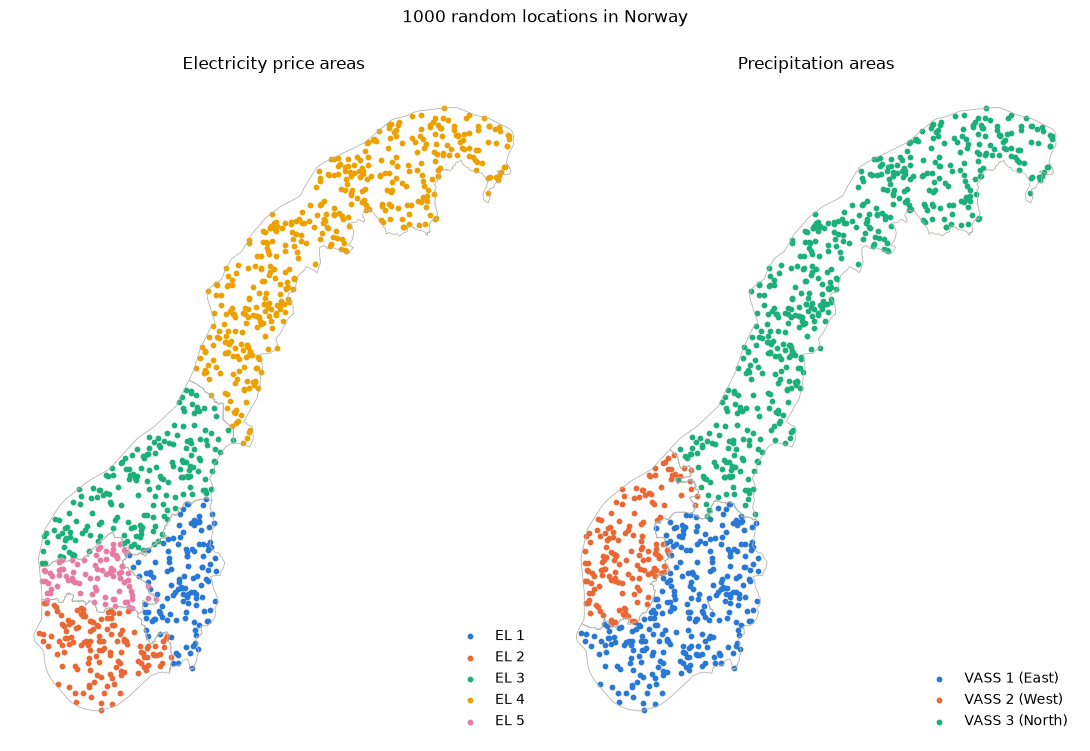

In [8]:
# Map of the sampled locations, once per area type
EL_COLORS = dict(zip(sorted(price_areas["el_area"]), ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
VASS_COLORS = dict(zip(sorted(set(REGION_TO_VASS.values())), ["#2a78d6", "#eb6834", "#1baf7a"]))
VASS_LABELS = {"VASS 1": "VASS 1 (East)", "VASS 2": "VASS 2 (West)", "VASS 3": "VASS 3 (North)"}

fig, axes = plt.subplots(1, 2, figsize=(11, 8), sharex=True, sharey=True)

for ax, areas, column, colors, title in [
    (axes[0], price_areas, "el_area", EL_COLORS, "Electricity price areas"),
    (axes[1], nve_regions.dissolve("vass_area").reset_index(), "vass_area", VASS_COLORS, "Precipitation areas"),
]:
    areas.boundary.plot(ax=ax, color="#b5b4ad", linewidth=0.6)
    for area, group in samples.groupby(column):
        group.plot(ax=ax, color=colors[area], markersize=10, label=VASS_LABELS.get(area, area))
    ax.set_title(title)
    ax.set_axis_off()
    ax.legend(loc="lower right", frameon=False)

fig.suptitle(f"{N_POINTS} random locations in Norway")
plt.tight_layout()
plt.show()


In [9]:
# save the locations for the Streamlit app, which reads them instead of sampling again
samples.drop(columns="geometry").rename_axis("point_id").to_csv("../Data/sample_locations.csv")

## Weather data from Open-Meteo (ERA5)

The weather comes from Open-Meteo's historical API (ERA5 model). `download_weather` takes a region (`EL 1`–`EL 5` or `VASS 1`–`VASS 3`) and a time period, and downloads daily weather for every sampled location in that region.

**API limit:** 10,000 calls per day. A big request counts as several calls: about `days / 14 × variables / 10` per location. One year for one location costs about 26 calls, so all 1000 locations would cost about 26,000 calls, which is too much for one day.

**To stay under the limit, the function:**
- saves every download in `No_sync/era5/`, so nothing is downloaded twice
- counts the calls and stops before the daily limit, then continues next time it runs
- waits between requests, and tries again if the API is busy
- can show the price first with `dry_run=True`

ERA5 is about 5 days behind, so dates that are too recent are skipped. Locations in the same ERA5 grid cell are still downloaded separately, because Open-Meteo adjusts the temperature to each location's elevation.

In [10]:
import hashlib
import json
import time
from datetime import date, datetime, timedelta, timezone
from pathlib import Path

ERA5_URL = "https://archive-api.open-meteo.com/v1/archive"

# Exactly 10 variables:
DAILY_VARIABLES = [
    "precipitation_sum",           # rain and snow together
    "rain_sum",                    
    "snowfall_sum",                # snow stored until it melts
    "precipitation_hours",         # hours with precipitation
    "temperature_2m_mean",        
    "wind_speed_10m_mean",        
    "shortwave_radiation_sum",     # drives snowmelt
    "et0_fao_evapotranspiration",  # water lost to the air
]

DAILY_BUDGET = 9000     # stay under the limit of 10,000, in case other things use the API
HOURLY_LIMIT = 5000
ERA5_DELAY_DAYS = 7     # 5 days according to the docs, with some margin

CACHE_DIR = Path("../No_sync/era5")   # gitignored
USAGE_FILE = CACHE_DIR / "usage.json"


In [11]:
# counts API calls per day
def calls_used_today():
    today = str(datetime.now(timezone.utc).date())
    if not USAGE_FILE.exists():
        return 0.0
    return json.loads(USAGE_FILE.read_text()).get(today, 0.0)

# add the cost of a request to the days total
def add_calls(cost):
    today = str(datetime.now(timezone.utc).date())
    usage = json.loads(USAGE_FILE.read_text()) if USAGE_FILE.exists() else {}
    usage[today] = usage.get(today, 0.0) + cost
    USAGE_FILE.write_text(json.dumps(usage))

# Look up the sampled locations for a region
def locations_in_region(region):
    column = "el_area" if region.startswith("EL") else "vass_area"
    points = samples.loc[samples[column] == region, ["lon", "lat", "el_area", "vass_area"]]
    if points.empty:
        raise ValueError(f"Unknown region: {region}")
    return points

# Split an interval into one (start, end) pair per calendar year
def split_by_year(start, end):
    return [
        (max(start, date(year, 1, 1)), min(end, date(year, 12, 31)))
        for year in range(start.year, end.year + 1)
    ]

# the cost in api call for of one request for one location
def estimate_cost(chunk_start, chunk_end, n_variables):
    days = (chunk_end - chunk_start).days + 1
    return max(days / 14 * n_variables / 10, 1)

#file for one location and year. The hash keeps different variable lists apart
def cache_path(lon, lat, chunk_start, chunk_end, variables):
    variables_id = hashlib.md5(",".join(variables).encode()).hexdigest()[:8]
    return CACHE_DIR / variables_id / f"{lat:.4f}_{lon:.4f}_{chunk_start}_{chunk_end}.parquet"

# the actual api request
def fetch_location(lon, lat, chunk_start, chunk_end, variables):
    """Download one location and year. Returns the data and the real cost in calls."""
    resp = requests.get(ERA5_URL, timeout=20, params={   # a normal answer takes under a second
        "latitude": lat,
        "longitude": lon,
        "start_date": chunk_start,
        "end_date": chunk_end,
        "daily": ",".join(variables),
        "models": "era5",
        "timezone": "Europe/Oslo",   # days match the Norwegian calendar, as in part 2
        "wind_speed_unit": "ms",
    })
    resp.raise_for_status()
    result = resp.json()
    data = pd.DataFrame(result["daily"]).rename(columns={"time": "date"})
    data["date"] = pd.to_datetime(data["date"])
    # the ERA5 grid cell that was actually used, which is often not at the exact location
    data["grid_lat"] = result["latitude"]
    data["grid_lon"] = result["longitude"]
    data["elevation"] = result["elevation"]
    return data, float(resp.headers["X-RateLimit-Cost"])


In [12]:

# finding out if the server is busy or there is something else going on
def is_busy(error):
    status = error.response.status_code
    return status >= 500 or (status == 429 and "concurrent" in error.response.text)

# try again if the server is busy
def fetch_with_retries(lon, lat, chunk_start, chunk_end, variables, attempts=6):
    for attempt in range(1, attempts + 1):
        try:
            return fetch_location(lon, lat, chunk_start, chunk_end, variables)
        except (requests.Timeout, requests.ConnectionError, requests.HTTPError) as error:
            if isinstance(error, requests.HTTPError) and not is_busy(error):
                raise
            if attempt == attempts:
                raise
            wait = min(30 * 2 ** (attempt - 1), 300)
            print(f"  the API is busy, trying again in {wait} s (attempt {attempt} of {attempts})")
            time.sleep(wait)

# dowloading data: region + time intervall in, weather data out
def download_weather(region, start, end, variables=DAILY_VARIABLES, dry_run=False):
    
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    start = date.fromisoformat(start)
    end = date.fromisoformat(end)

    latest = date.today() - timedelta(days=ERA5_DELAY_DAYS)
    if end > latest:
        print(f"ERA5 is not available that late, using {latest} as the end date")
        end = latest

    points = locations_in_region(region)
    chunks = split_by_year(start, end)

    # one job per location and year, the ones already saved are skipped
    jobs = [
        (point_id, point.lon, point.lat, chunk_start, chunk_end)
        for point_id, point in points.iterrows()
        for chunk_start, chunk_end in chunks
    ]
    paths = {job: cache_path(job[1], job[2], job[3], job[4], variables) for job in jobs}
    todo = [job for job in jobs if not paths[job].exists()]

    cost = sum(estimate_cost(job[3], job[4], len(variables)) for job in todo)
    used = calls_used_today()
    print(f"{region}: {len(points)} locations, {len(jobs) - len(todo)} of {len(jobs)} requests already saved")
    print(f"Cost of the rest: {cost:.0f} calls. Used today: {used:.0f} of {DAILY_BUDGET}.")
    if dry_run:
        return None

    done = 0
    for job in todo:
        point_id, lon, lat, chunk_start, chunk_end = job
        estimate = estimate_cost(chunk_start, chunk_end, len(variables))
        if calls_used_today() + estimate > DAILY_BUDGET:
            print(f"Daily budget reached after {done} of {len(todo)} requests. Run it again tomorrow.")
            break
        try:
            data, real_cost = fetch_with_retries(lon, lat, chunk_start, chunk_end, variables)
        except requests.HTTPError as error:
            if error.response.status_code == 429 or is_busy(error):
                print(f"Stopped after {done} of {len(todo)} requests: {error.response.status_code} {error.response.text}. Run it again later.")
                break
            raise
        except (requests.Timeout, requests.ConnectionError):
            print(f"The API is not answering, stopped after {done} of {len(todo)} requests. Run it again later.")
            break

        paths[job].parent.mkdir(exist_ok=True)
        data.to_parquet(paths[job])
        add_calls(real_cost)
        done += 1
        if done % 25 == 0:
            print(f"  {done} of {len(todo)} requests done")
        time.sleep(real_cost * 3600 / HOURLY_LIMIT)   # stays under the hourly and minute limits

    saved = [
        pd.read_parquet(paths[job]).assign(point_id=job[0], region=region)
        for job in jobs if paths[job].exists()
    ]
    if len(saved) < len(jobs):
        print(f"Note: {len(jobs) - len(saved)} of {len(jobs)} requests are still missing from this result")
    return pd.concat(saved, ignore_index=True) if saved else pd.DataFrame()


### NO 3 (EL 3) for 2024


In [13]:
# downloading the NO3 data
weather_el3 = download_weather("EL 3", "2024-01-01", "2024-12-31")
print(weather_el3.shape)
print(f"Used today: {calls_used_today():.0f} calls")
weather_el3.head()


EL 3: 197 locations, 0 of 197 requests already saved
Cost of the rest: 4120 calls. Used today: 0 of 9000.
  25 of 197 requests done
  50 of 197 requests done
  75 of 197 requests done
  100 of 197 requests done
  125 of 197 requests done
  150 of 197 requests done
  175 of 197 requests done
(72102, 14)
Used today: 4120 calls


,date,precipitation_sum,rain_sum,snowfall_sum,precipitation_hours,temperature_2m_mean,wind_speed_10m_mean,shortwave_radiation_sum,et0_fao_evapotranspiration,grid_lat,grid_lon,elevation,point_id,region
0,2024-01-01,0.5,0.3,0.14,4.0,1.9,6.15,0.52,1.34,61.25,5.5,137.0,8,EL 3
1,2024-01-02,0.3,0.3,0.00,2.0,-1.1,6.16,0.79,1.15,61.25,5.5,137.0,8,EL 3
2,2024-01-03,0.0,0.0,0.00,0.0,-5.6,5.62,0.92,0.94,61.25,5.5,137.0,8,EL 3
3,2024-01-04,0.0,0.0,0.00,0.0,-7.0,3.18,0.62,0.56,61.25,5.5,137.0,8,EL 3
4,2024-01-05,0.0,0.0,0.00,0.0,-11.1,2.66,0.97,0.24,61.25,5.5,137.0,8,EL 3


## Outliers and anomalies in precipitation

Goal: fining the days with unusually much or little percipitation.

but i need to remove the seasonal pattern becaus much or little rain is normal some parts of the year.

In [14]:
from scipy.fft import dct, idct

# fining the day with unusual average percipitation, using DCT and SPC
def precipitation_outliers(weather, cutoff=10, n_std=3.0, column="precipitation_sum"):
    daily = weather.groupby("date")[column].mean().sort_index()
    values = daily.to_numpy()
    n_days = len(values)
    if not 1 <= cutoff < n_days:
        raise ValueError(f"cutoff must be between 1 and {n_days - 1}")

    # low pass: keep the first `cutoff` coefficients, which give the seasonal curve
    coefficients = dct(values, norm="ortho")
    coefficients[cutoff:] = 0
    seasonal = idct(coefficients, norm="ortho")
    satv = values - seasonal   # high-pass part

    # robust centre and spread of the SATV for the whole period
    centre = np.median(satv)
    spread = 1.4826 * np.median(np.abs(satv - centre))
    upper = seasonal + centre + n_std * spread
    lower = seasonal + centre - n_std * spread
    is_outlier = (values > upper) | (values < lower)

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(daily.index, values, color="#2a78d6", linewidth=1, label="Average precipitation")
    ax.plot(daily.index, upper, color="#52514e", linewidth=1, linestyle="--", label=f"SPC boundaries (±{n_std:g} robust SD)")
    ax.plot(daily.index, lower, color="#52514e", linewidth=1, linestyle="--")
    ax.scatter(daily.index[is_outlier], values[is_outlier], color="#eb6834", s=30, zorder=3,
               label=f"Outliers ({is_outlier.sum()})")
    ax.axhline(0, color="#b5b4ad", linewidth=0.6)
    region = ", ".join(weather["region"].unique()) if "region" in weather else "all locations"
    ax.set_title(f"Daily precipitation, average over {weather['point_id'].nunique() if 'point_id' in weather else 1} locations ({region})")
    ax.set_xlabel("Date")
    ax.set_ylabel("Precipitation (mm per day)")
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.close(fig)   # show it where the function is called, not twice

    outliers = pd.DataFrame({
        "precipitation": values,
        "seasonal": seasonal,
        "lower": lower,
        "upper": upper,
        "satv": satv,
    }, index=daily.index)[is_outlier]
    outliers["direction"] = np.where(outliers["precipitation"] > outliers["upper"], "above", "below")

    summary = {
        "days": n_days,
        "outliers": int(is_outlier.sum()),
        "share_outliers": round(float(is_outlier.mean()), 3),
        "above": int((outliers["direction"] == "above").sum()),
        "below": int((outliers["direction"] == "below").sum()),
        "seasonal_cycles_longer_than_days": round(2 * n_days / cutoff, 1),
        "satv_median": round(float(centre), 2),
        "satv_robust_sd": round(float(spread), 2),
        "precipitation_in_outliers_mm": round(float(outliers["precipitation"].sum()), 1),
        "share_of_total_precipitation": round(float(outliers["precipitation"].sum() / values.sum()), 3),
    }
    return fig, outliers.round(2), summary


### NO 3 (EL 3) in 2024


{'days': 366, 'outliers': 18, 'share_outliers': 0.049, 'above': 18, 'below': 0, 'seasonal_cycles_longer_than_days': 73.2, 'satv_median': -1.1, 'satv_robust_sd': 3.54, 'precipitation_in_outliers_mm': 351.9, 'share_of_total_precipitation': 0.198}


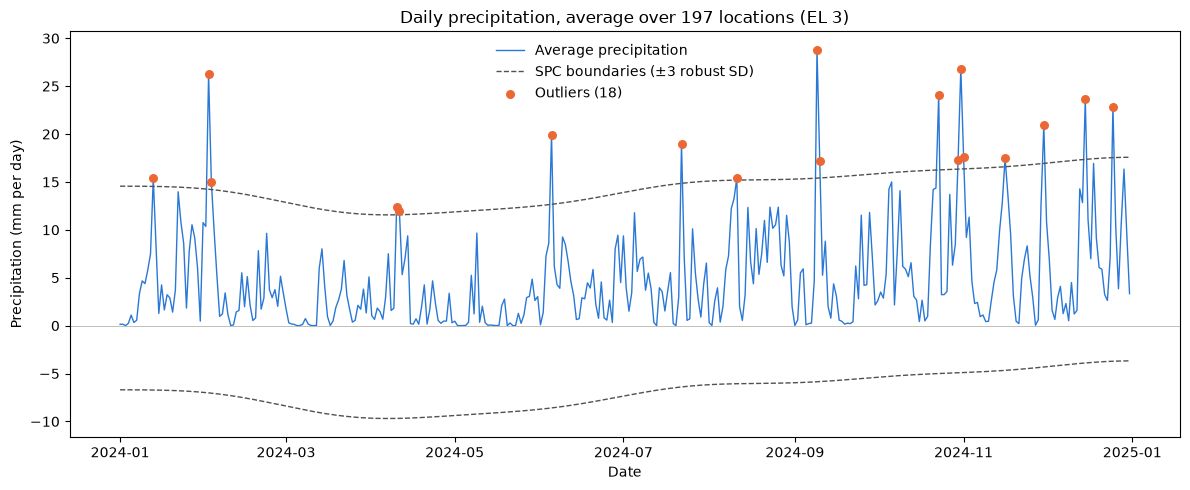

In [15]:
# running the outlier function on the real data
fig, outliers_el3, summary_el3 = precipitation_outliers(weather_el3)
print(summary_el3)
fig


In [16]:
# the outlier days, heaviest first
outliers_el3.sort_values("precipitation", ascending=False)


,precipitation,seasonal,lower,upper,satv,direction
date,,,,,,
2024-09-09,28.80,5.87,-5.86,15.40,22.92,above
2024-10-31,26.83,6.83,-4.91,16.35,20.01,above
2024-02-02,26.23,4.71,-7.02,14.24,21.51,above
2024-10-23,24.09,6.73,-5.00,16.26,17.36,above
2024-12-15,23.62,7.83,-3.90,17.36,15.78,above
2024-12-25,22.87,8.02,-3.72,17.54,14.85,above
2024-11-30,20.91,7.41,-4.32,16.93,13.49,above
2024-06-05,19.89,3.14,-8.59,12.66,16.75,above
2024-07-22,18.98,5.33,-6.40,14.86,13.65,above


## Temperature anomalies with Local Outlier Factor

Goal: finding days with unusual temperature 

using LOF to check if a point is far from others. this is how it is defining it as an anomaly.


In [17]:
from sklearn.neighbors import LocalOutlierFactor
#Find unusual days in the average temperature with the Local Outlier Factor method
def temperature_anomalies(weather, proportion=0.01, n_neighbors=20, column="temperature_2m_mean"):
    if not 0 < proportion <= 0.5:
        raise ValueError("proportion must be above 0 and at most 0.5")

    daily = weather.groupby("date")[column].mean().sort_index()
    values = daily.to_numpy()
    days = np.arange(len(values))

    # date and temperature, standardised so both count equally
    features = np.column_stack([
        (days - days.mean()) / days.std(),
        (values - values.mean()) / values.std(),
    ])
    lof = LocalOutlierFactor(n_neighbors=n_neighbors, contamination=proportion)
    is_outlier = lof.fit_predict(features) == -1

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(daily.index, values, color="#2a78d6", linewidth=1, label="Average temperature")
    ax.scatter(daily.index[is_outlier], values[is_outlier], color="#eb6834", s=30, zorder=3,
               label=f"LOF outliers ({is_outlier.sum()})")
    region = ", ".join(weather["region"].unique()) if "region" in weather else "all locations"
    n_locations = weather["point_id"].nunique() if "point_id" in weather else 1
    ax.set_title(f"Daily mean temperature, average over {n_locations} locations ({region})")
    ax.set_xlabel("Date")
    ax.set_ylabel("Temperature (°C)")
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.close(fig)   # show it where the function is called, not twice

    # compare each outlier with the median of the two weeks around it, to say if it was warm or cold
    local_median = daily.rolling(15, center=True, min_periods=1).median()
    outliers = pd.DataFrame({
        "temperature": values,
        "local_median": local_median.to_numpy(),
        "lof_score": -lof.negative_outlier_factor_,   # around 1 is normal, higher is more unusual
    }, index=daily.index)[is_outlier]
    outliers["difference"] = outliers["temperature"] - outliers["local_median"]
    outliers["direction"] = np.where(outliers["difference"] > 0, "warmer", "colder")

    summary = {
        "days": len(values),
        "outliers": int(is_outlier.sum()),
        "share_outliers": round(float(is_outlier.mean()), 3),
        "warmer": int((outliers["direction"] == "warmer").sum()),
        "colder": int((outliers["direction"] == "colder").sum()),
        "largest_difference_c": round(float(outliers["difference"].abs().max()), 1) if len(outliers) else None,
        "lof_threshold": round(float(-lof.offset_), 2),
    }
    return fig, outliers.round(2), summary


### NO 3 (EL 3) in 2024


{'days': 366, 'outliers': 4, 'share_outliers': 0.011, 'warmer': 1, 'colder': 3, 'largest_difference_c': 6.7, 'lof_threshold': 1.61}


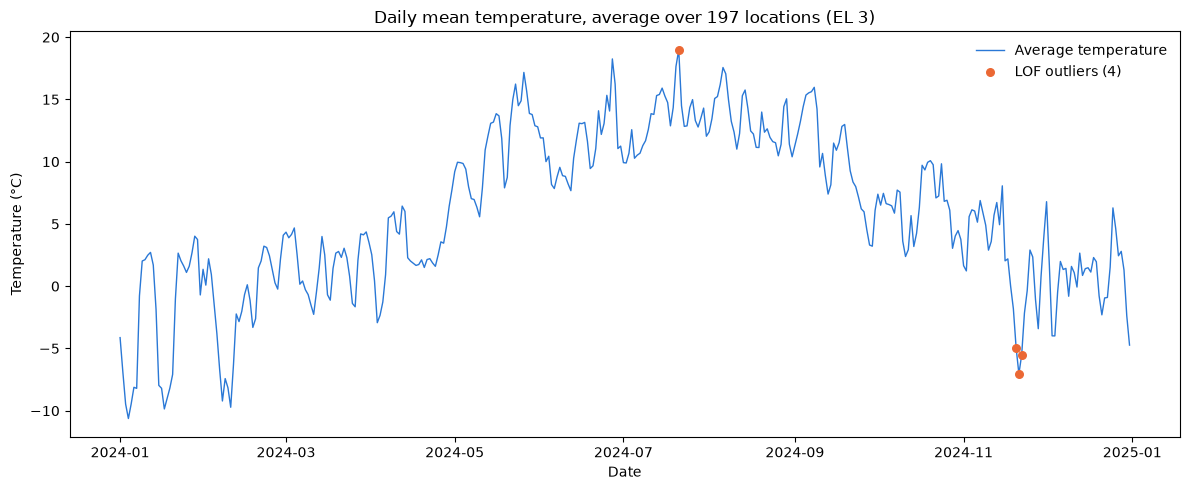

In [18]:
# running LOF on the real data
fig, anomalies_el3, anomaly_summary_el3 = temperature_anomalies(weather_el3)
print(anomaly_summary_el3)
fig


In [19]:
anomalies_el3


,temperature,local_median,lof_score,difference,direction
date,,,,,
2024-07-21,18.99,14.49,1.75,4.49,warmer
2024-11-20,-4.96,0.01,1.62,-4.97,colder
2024-11-21,-7.05,-0.36,2.06,-6.68,colder
2024-11-22,-5.52,-0.36,1.72,-5.16,colder


## Seasonal-Trend decomposition with LOESS (STL)

Goal: splitting the reservoir fill ratio into three parts

- Trend
- Seasonal
- Residual

by using STL which is using LOESS, which is a kind of smoothing to find each part.

In [20]:
from statsmodels.tsa.seasonal import STL

#STL decomposition of the weekly degree of filling for one area
# data is weekly so one year is period = 52
def stl_fill_ratio(reservoirs, area="EL 3", seasonal=13, trend=105, robust=True, period=52): 
    if seasonal < 7 or seasonal % 2 == 0:
        raise ValueError("seasonal must be odd and at least 7")
    if trend <= period or trend % 2 == 0:
        raise ValueError(f"trend must be odd and longer than the period ({period})")

    area_type, area_number = area.split()
    rows = reservoirs[(reservoirs["omrType"] == area_type) & (reservoirs["omrnr"] == int(area_number))]
    if rows.empty:
        raise ValueError(f"No data for area {area}")
    fill = rows.set_index(pd.to_datetime(rows["dato_Id"]))["fyllingsgrad"].sort_index()

    result = STL(fill, period=period, seasonal=seasonal, trend=trend, robust=robust).fit()

    parts = [
        ("Observed", result.observed),
        ("Trend", result.trend),
        ("Seasonal", result.seasonal),
        ("Residual", result.resid),
    ]
    fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
    for ax, (name, values) in zip(axes, parts):
        ax.plot(fill.index, values, color="#2a78d6", linewidth=0.8)
        ax.set_ylabel(name)
    for ax in axes[2:]:
        ax.axhline(0, color="#b5b4ad", linewidth=0.6)   # seasonal and residual vary around 0
    axes[-1].set_xlabel("Date")
    fig.suptitle(f"STL of the degree of filling for {area} "
                 f"(seasonal={seasonal}, trend={trend}, robust={robust})")
    plt.tight_layout()
    plt.close(fig)   # show it where the function is called, not twice
    return fig


### NO 3 (EL 3), 1995–2026


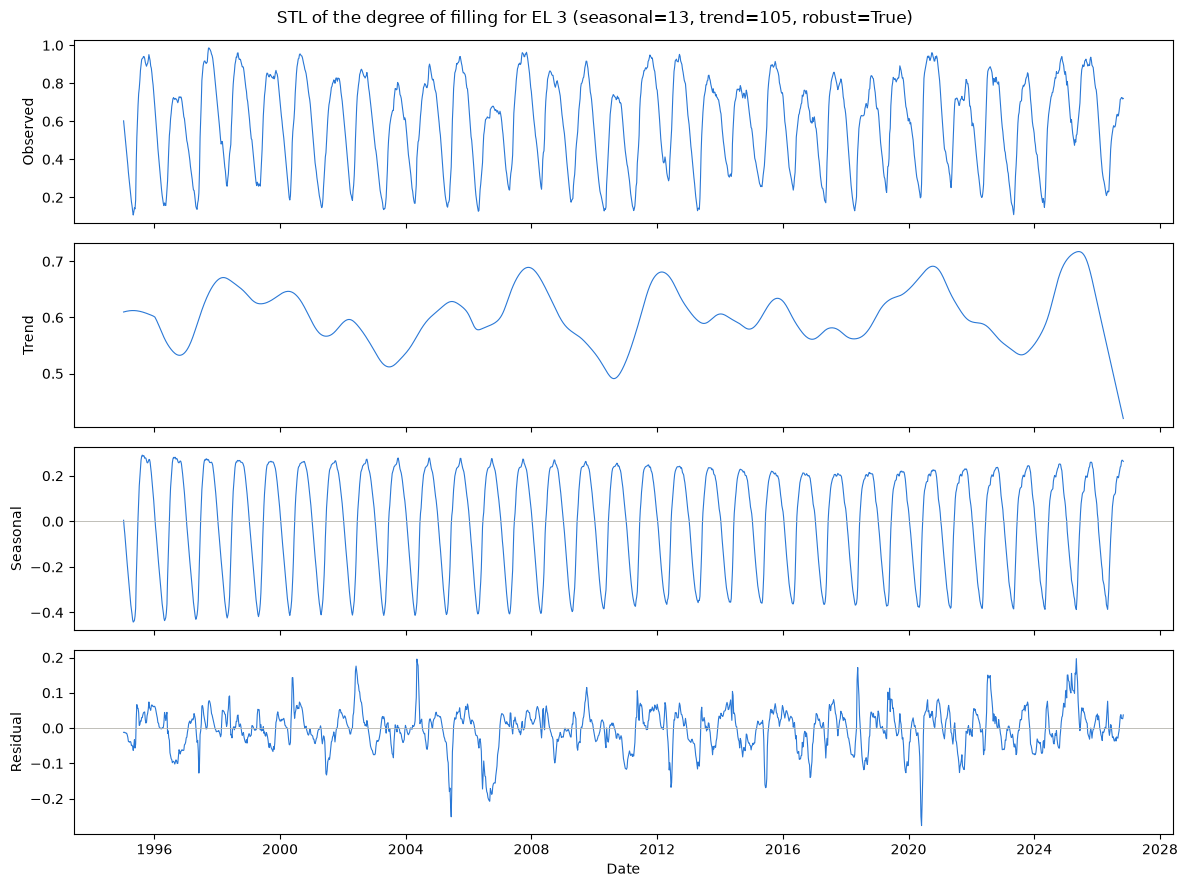

In [21]:
#testing on the real data
stl_fill_ratio(reservoirs, area="EL 3")


## Spectrogram

Goal: see which cycles ar in the fill ratio, how strong they are, and whether that changes over time.

this is done by

1. cutting the data into overlapping pieces
2. for each piece measure how strong each cycles is
3. plot


In [22]:
from scipy.signal import spectrogram

#Spectrogram of the weekly degree of filling for one area
def spectrogram_fill_ratio(reservoirs, area="EL 3", window=156, overlap=130, max_frequency=6):
    area_type, area_number = area.split()
    rows = reservoirs[(reservoirs["omrType"] == area_type) & (reservoirs["omrnr"] == int(area_number))]
    if rows.empty:
        raise ValueError(f"No data for area {area}")
    fill = rows.set_index(pd.to_datetime(rows["dato_Id"]))["fyllingsgrad"].sort_index()

    if not 2 <= window <= len(fill):
        raise ValueError(f"window must be between 2 and {len(fill)} weeks")
    if not 0 <= overlap < window:
        raise ValueError("overlap must be at least 0 and less than window")

    # 52 samples per year, so the frequencies come out in cycles per year
    frequencies, times, power = spectrogram(fill.to_numpy(), fs=52, nperseg=window, noverlap=overlap)
    power_db = 10 * np.log10(power + 1e-12)   # avoid log(0)
    window_centres = fill.index[0] + pd.to_timedelta(times * 52 * 7, unit="D")   # years -> dates

    fig, ax = plt.subplots(figsize=(12, 5))
    # colour the top 50 dB, a few almost empty cells would otherwise stretch the scale
    mesh = ax.pcolormesh(window_centres, frequencies, power_db, shading="nearest", cmap="Blues",
                         vmin=power_db.max() - 50, vmax=power_db.max())
    fig.colorbar(mesh, ax=ax, label="Power (dB)")
    ax.set_ylim(0, max_frequency)
    ax.set_xlabel("Date (centre of the window)")
    ax.set_ylabel("Frequency (cycles per year)")
    ax.set_title(f"Spectrogram of the degree of filling for {area} "
                 f"(window {window} weeks, overlap {overlap} weeks)")
    plt.tight_layout()
    plt.close(fig)   # show it where the function is called, not twice
    return fig


### NO 3 (EL 3), 1995–2026


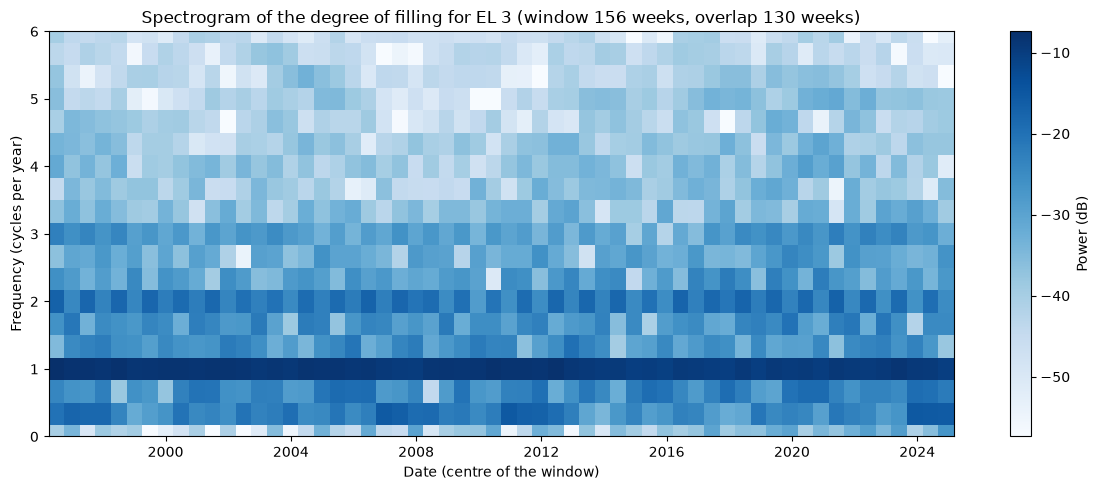

In [23]:
# on the real data
spectrogram_fill_ratio(reservoirs, area="EL 3")


## Log


I started with downloading the shapefiles from NVE Atlas. These represented the electricity areas and precipitation areas that correspond to the Magasinstatistikk data used earlier in the project. Since we only have VASS 1, 2, and 3, I needed to combine some of the regions. Then I verified that the areas match up with the power capacity for whole Norway.
Then I sampled 1000 random locations in Norway, and labelled them with the electricity price area and the precipitation area they belong to. I sampled uniformly so that the largest areas have more locations.

Then I continued to the weather data. I used the ERA5 model from Open-Meteo to get the daily weather for each sampled location. The biggest challenge here was to make sure that I stayed under the daily, hourly and minute limit. This is solved in different ways. For example by saving all the locations and years as a file in No_sync/era5/, so that I don't have to download the same data twice. I also made a dry run option, so that I can see how many calls it would take before actually downloading the data. And I also made it so that it counts the calls and stops before the limit, and continues next time it runs. Reaching the limit was no problem for this part.

When the data was downloaded, then I started doing some calculations with it. First I did anomaly detection. This was done by removing the seasons, then measuring the variation, drawing boundaries and then flagging points outside of these as outliers. Then I did LOF on the temperature data to find points that are far from the others, and flag them as outliers. Then I did STL on the reservoir fill ratio to filter out the trend, seasonality and the residuals. Lastly I created a spectrogram to see which cycles are in the fill ratio.

Then I created the new pages for the app: one for weather data, one for outliers and anomaly detection and one for the STL and spectrogram. I created a Streamlit config file to make the app look as I want. I also created two new utils files: analysis_utils.py for the analysis functions and weather_utils.py for the weather download functions.


## AI usage


For this part I used AI to generate, read and fix code for the notebook and the Streamlit app files. I used it to help me set up the download of the weather data, and explaining how to handle the shapefiles for the location data.